# Relatório de métricas do teste03 — YOLOv8n

Este relatório analisa o detector YOLOv8n treinado pelo `teste03.py` por 100 épocas, com imagens do `dataset_yolo`, resolução 640 e uma classe (`lixo`). O histórico de treino vem de `runs/detect/yolov8n_com_lixo/results.csv`; a avaliação final reexecuta `best.pt` no split `val`.

Como o teste03 é de **detecção por caixas**, o relatório apresenta precisão, recall, mAP@50 e mAP@50–95 de caixas. Métricas de máscaras não se aplicam a este modelo. O melhor valor histórico de cada métrica pode ocorrer em épocas diferentes; esses valores não devem ser confundidos com a avaliação conjunta do checkpoint `best.pt`, escolhido pelo critério de fitness do treinamento.

**Interpretação:** precisão e recall descrevem aspectos diferentes dos acertos; mAP@50 mede a precisão média com IoU 0,50 e mAP@50–95 agrega IoUs de 0,50 a 0,95. Acurácia convencional não é uma métrica adequada como resumo principal para detecção de objetos.

In [1]:
from collections import Counter
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display
from PIL import Image as PILImage
from ultralytics import YOLO

PASTA_PROJETO = Path.cwd()
PASTA_EXECUCAO = PASTA_PROJETO / "runs" / "detect" / "yolov8n_com_lixo"
ARQUIVO_HISTORICO = PASTA_EXECUCAO / "results.csv"
ARQUIVO_BEST = PASTA_EXECUCAO / "weights" / "best.pt"
ARQUIVO_DATASET = PASTA_PROJETO / "dataset_yolo" / "dataset.yaml"
TAMANHO_IMAGEM = 640
BATCH_AVALIACAO = 1

for caminho in (ARQUIVO_HISTORICO, ARQUIVO_BEST, ARQUIVO_DATASET):
    if not caminho.is_file():
        raise FileNotFoundError(f"Artefato do teste03 não encontrado: {caminho}")

historico = pd.read_csv(ARQUIVO_HISTORICO)
historico.columns = historico.columns.str.strip()
if historico.empty:
    raise ValueError(f"O histórico está vazio: {ARQUIVO_HISTORICO}")

configuracao_dataset = yaml.safe_load(ARQUIVO_DATASET.read_text(encoding="utf-8"))
raiz_dataset = Path(configuracao_dataset.get("path", ARQUIVO_DATASET.parent))
if not raiz_dataset.is_absolute():
    raiz_dataset = (ARQUIVO_DATASET.parent / raiz_dataset).resolve()
if not raiz_dataset.is_dir():
    raiz_dataset = ARQUIVO_DATASET.parent.resolve()
configuracao_dataset["path"] = raiz_dataset.as_posix()

nomes_classes = configuracao_dataset.get("names", {})
if isinstance(nomes_classes, list):
    nomes_classes = {indice: nome for indice, nome in enumerate(nomes_classes)}
else:
    nomes_classes = {int(indice): nome for indice, nome in nomes_classes.items()}
if nomes_classes != {0: "lixo"}:
    raise ValueError(f"Esperada a classe única 'lixo'; configuração atual: {nomes_classes}")

PASTA_IMAGENS_VALIDACAO = raiz_dataset / configuracao_dataset["val"]
PASTA_ROTULOS_VALIDACAO = raiz_dataset / "labels" / "val"
for caminho in (PASTA_IMAGENS_VALIDACAO, PASTA_ROTULOS_VALIDACAO):
    if not caminho.is_dir():
        raise FileNotFoundError(f"Pasta da validação não encontrada: {caminho}")

print(f"Execução analisada: {PASTA_EXECUCAO.name}")
print(f"Épocas registradas: {len(historico)}")
print(f"Checkpoint avaliado: {ARQUIVO_BEST}")
print(f"Dataset de validação: {PASTA_IMAGENS_VALIDACAO}")

Execução analisada: yolov8n_com_lixo
Épocas registradas: 100
Checkpoint avaliado: c:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\runs\detect\yolov8n_com_lixo\weights\best.pt
Dataset de validação: C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\dataset_yolo\images\val


,Melhor valor no histórico,Época do melhor valor,Valor na última época
Métrica,,,
Precisão caixas,0.8519,76,0.8304
Recall caixas,0.6326,74,0.6124
mAP50 caixas,0.7074,80,0.6988
mAP50-95 caixas,0.5647,87,0.5611


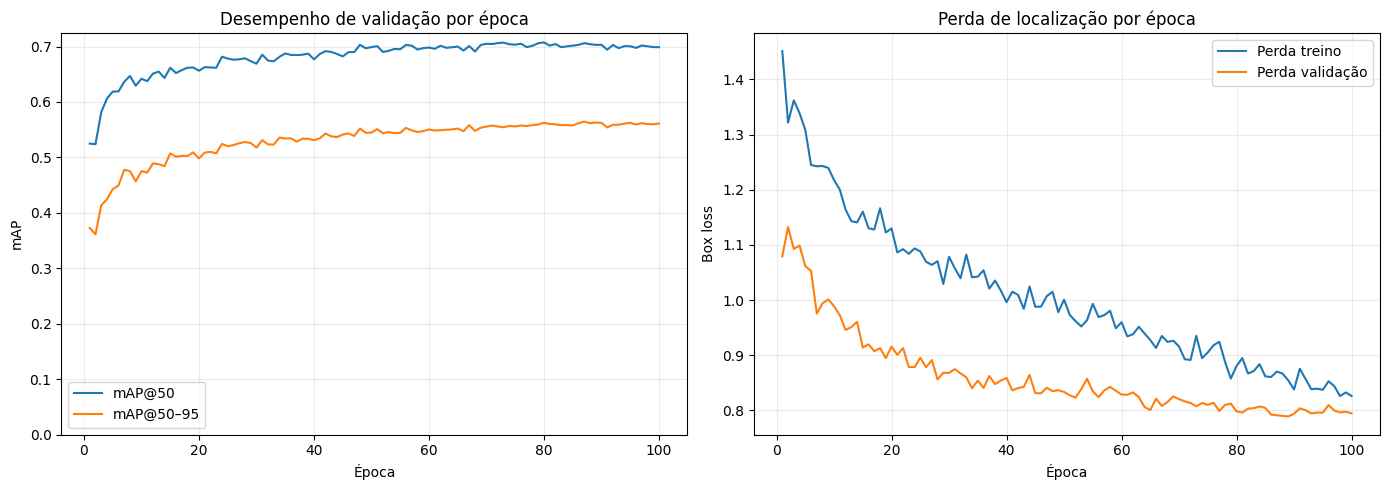

In [2]:
colunas_historico = {
    "Precisão caixas": "metrics/precision(B)",
    "Recall caixas": "metrics/recall(B)",
    "mAP50 caixas": "metrics/mAP50(B)",
    "mAP50-95 caixas": "metrics/mAP50-95(B)",
}
colunas_ausentes = [coluna for coluna in colunas_historico.values() if coluna not in historico]
if colunas_ausentes:
    raise KeyError(f"Colunas esperadas não encontradas em results.csv: {colunas_ausentes}")

linhas_resumo = []
for nome_metrica, coluna in colunas_historico.items():
    indice_melhor = historico[coluna].idxmax()
    linhas_resumo.append({
        "Métrica": nome_metrica,
        "Melhor valor no histórico": historico.loc[indice_melhor, coluna],
        "Época do melhor valor": int(historico.loc[indice_melhor, "epoch"]),
        "Valor na última época": historico.iloc[-1][coluna],
    })

resumo_historico = pd.DataFrame(linhas_resumo).set_index("Métrica")
display(resumo_historico.style.format({
    "Melhor valor no histórico": "{:.4f}",
    "Valor na última época": "{:.4f}",
}))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].plot(historico["epoch"], historico["metrics/mAP50(B)"], label="mAP@50")
eixos[0].plot(historico["epoch"], historico["metrics/mAP50-95(B)"], label="mAP@50–95")
eixos[0].set(title="Desempenho de validação por época", xlabel="Época", ylabel="mAP")
eixos[0].set_ylim(bottom=0)
eixos[0].grid(alpha=0.25)
eixos[0].legend()

eixos[1].plot(historico["epoch"], historico["train/box_loss"], label="Perda treino")
eixos[1].plot(historico["epoch"], historico["val/box_loss"], label="Perda validação")
eixos[1].set(title="Perda de localização por época", xlabel="Época", ylabel="Box loss")
eixos[1].grid(alpha=0.25)
eixos[1].legend()
fig.tight_layout()
plt.show()

In [3]:
modelo_avaliado = YOLO(str(ARQUIVO_BEST))
PASTA_RESULTADO_VALIDACAO = PASTA_EXECUCAO / "metricas_validacao" / "best_checkpoint"

with tempfile.TemporaryDirectory() as diretorio_temporario:
    arquivo_dataset_local = Path(diretorio_temporario) / "dataset.yaml"
    arquivo_dataset_local.write_text(
        yaml.safe_dump(configuracao_dataset, allow_unicode=True, sort_keys=False),
        encoding="utf-8",
    )
    metricas_validacao = modelo_avaliado.val(
        data=str(arquivo_dataset_local),
        split="val",
        imgsz=TAMANHO_IMAGEM,
        batch=BATCH_AVALIACAO,
        device="cpu",
        plots=True,
        verbose=False,
        workers=0,
        project=str(PASTA_EXECUCAO / "metricas_validacao"),
        name="best_checkpoint",
        exist_ok=True,
    )

precisao, recall, map50, map50_95 = metricas_validacao.box.mean_results()
metricas_gerais = pd.DataFrame(
    [{
        "Precisão": precisao,
        "Recall": recall,
        "mAP@50": map50,
        "mAP@50-95": map50_95,
    }],
    index=["Caixas"],
)
display(metricas_gerais.style.format("{:.4f}"))
print(f"Matrizes e curvas da validação salvas em: {PASTA_RESULTADO_VALIDACAO}")

Ultralytics 8.4.202  Python-3.12.2 torch-2.15.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access  (ping: 0.1±0.1 ms, read: 226.1±249.2 MB/s, size: 1164.6 KB)
val: Scanning C:\Users\alexa\OneDrive\Área de Trabalho\TCC\Teste Base de Imagens TCC 03\dataset_yolo\labels\val.cache... 156 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 156/156  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 11/78 5.9it/s 1.7s<11.4s


error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\core\src\alloc.cpp:73: error: (-4:Insufficient memory) Failed to allocate 12330240 bytes in function 'cv::OutOfMemoryError'


In [ ]:
instancias_por_classe = Counter()
rotulos_vazios = 0
for arquivo_rotulo in PASTA_ROTULOS_VALIDACAO.rglob("*.txt"):
    linhas = [linha for linha in arquivo_rotulo.read_text(encoding="utf-8").splitlines() if linha.strip()]
    if not linhas:
        rotulos_vazios += 1
    for linha in linhas:
        indice_classe = int(linha.split(maxsplit=1)[0])
        if indice_classe not in nomes_classes:
            raise ValueError(f"ID de classe desconhecido no rótulo {arquivo_rotulo}: {indice_classe}")
        instancias_por_classe[indice_classe] += 1

extensoes_imagem = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
quantidade_imagens = sum(
    caminho.is_file() and not caminho.name.startswith(".") and caminho.suffix.lower() in extensoes_imagem
    for caminho in PASTA_IMAGENS_VALIDACAO.rglob("*")
)

linhas_classes = []
avaliacao = metricas_validacao.box
for indice_classe, nome_classe in nomes_classes.items():
    posicoes = [
        posicao for posicao, classe in enumerate(avaliacao.ap_class_index)
        if int(classe) == indice_classe
    ]
    if posicoes:
        posicao = posicoes[0]
        metricas_classe = {
            "Precisão": avaliacao.p[posicao],
            "Recall": avaliacao.r[posicao],
            "mAP@50": avaliacao.ap50[posicao],
            "mAP@50-95": avaliacao.ap[posicao].mean(),
        }
    else:
        metricas_classe = {nome: float("nan") for nome in ("Precisão", "Recall", "mAP@50", "mAP@50-95")}
    linhas_classes.append({
        "ID": indice_classe,
        "Classe": nome_classe,
        "Instâncias anotadas": instancias_por_classe[indice_classe],
        **metricas_classe,
    })

metricas_por_classe = pd.DataFrame(linhas_classes).set_index("ID")
display(metricas_por_classe.style.format(
    "{:.4f}",
    na_rep="N/A",
    subset=["Precisão", "Recall", "mAP@50", "mAP@50-95"],
))
print(f"Imagens de validação: {quantidade_imagens}")
print(f"Instâncias anotadas: {sum(instancias_por_classe.values())}")
print(f"Imagens sem caixas anotadas: {rotulos_vazios}")

resumo_csv = metricas_gerais.copy()
resumo_csv["Imagens de validação"] = quantidade_imagens
resumo_csv["Instâncias anotadas"] = sum(instancias_por_classe.values())
resumo_csv["Imagens sem caixas"] = rotulos_vazios
arquivo_csv_gerais = PASTA_EXECUCAO / "metricas_gerais.csv"
arquivo_csv_classes = PASTA_EXECUCAO / "metricas_por_classe.csv"
resumo_csv.to_csv(arquivo_csv_gerais, encoding="utf-8-sig")
metricas_por_classe.to_csv(arquivo_csv_classes, encoding="utf-8-sig")
print(f"Resumo salvo em: {arquivo_csv_gerais}")
print(f"Métricas por classe salvas em: {arquivo_csv_classes}")

## Leitura crítica dos resultados

- Precisão e recall devem ser analisados em conjunto: uma precisão maior que o recall pode indicar que parte dos objetos anotados não foi detectada.
- O teste03 usa uma única classe (`lixo`), então as métricas não separam tipos ou categorias de resíduos.
- A tabela do histórico mostra o máximo de cada métrica em épocas possivelmente diferentes e o valor da última época. A tabela de validação reavalia o mesmo checkpoint `best.pt` para precisão, recall e mAP no split `val`.
- A avaliação atual encontrou 156 imagens, 2 imagens sem caixas anotadas e 2.477 instâncias no split de validação. Esses números são recalculados pelo notebook; se o dataset mudar, atualize a interpretação.
- Como há poucas imagens negativas na validação, a avaliação de falsos positivos em cenas sem lixo é limitada. Para estimar melhor a generalização, use imagens independentes e aumente a quantidade de exemplos negativos.

Não há métricas de máscaras neste teste, pois o modelo foi treinado para detecção por caixas, não para segmentação.

In [ ]:
for nome_arquivo, titulo in (
    ("confusion_matrix.png", "Matriz de confusão — teste03"),
    ("confusion_matrix_normalized.png", "Matriz de confusão normalizada — teste03"),
):
    caminho = PASTA_RESULTADO_VALIDACAO / nome_arquivo
    if not caminho.is_file():
        raise FileNotFoundError(f"Matriz não encontrada: {caminho}. Execute primeiro a célula de avaliação.")
    print(titulo)
    display(PILImage.open(caminho))